# AI651 PA1 — Task 2: Autoformer Leaderboard (final pipeline)

**Pipeline in one line:** encoder–decoder Autoformer (series decomposition + Auto-Correlation) with the optional
covariates fed to both encoder (past) and decoder (known future horizon), a learned linear trend initialisation,
3-seed ensemble, refit on all 43,656 observations, forecasts clipped at 0 (non-negative target).

**Validation protocol (chronological, never the leaderboard):**
- *test blocks* — the last 52 non-overlapping 168-step blocks (~1 year) → all model comparisons;
- *inner validation* — the 26 blocks before that → early stopping only;
- *training* — everything earlier, every window (stride 1).

Autoformer components adapted from Wu et al. (2021) and the reference code at github.com/thuml/Autoformer;
delay aggregation follows the Question 1 implementation.

In [1]:
import math, random, copy, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
H = 168                 # forecast horizon (pred_len)
SEQ_LEN, LABEL_LEN = 168, 84
D_MODEL, HEADS, D_FF, KERNEL, DROPOUT = 16, 4, 32, 25, 0.05
LR, BATCH, MAX_EPOCHS, PATIENCE = 3e-4, 64, 20, 3
SEEDS = [0, 1, 2]
print(DEVICE, torch.__version__)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

/home/obaid/miniconda3/envs/edge_devices/lib/python3.11/site-packages/torch/cuda/__init__.py:68: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


cuda 2.14.0+cu130


## 1. Data and periodic structure

train 43656, external 43824, mean 98.2, std 90.8, max 994
ACF at lags 1, 12, 24, 48, 168: [0.966 0.57  0.401 0.158 0.028]
dominant period below 200 steps: 24.0


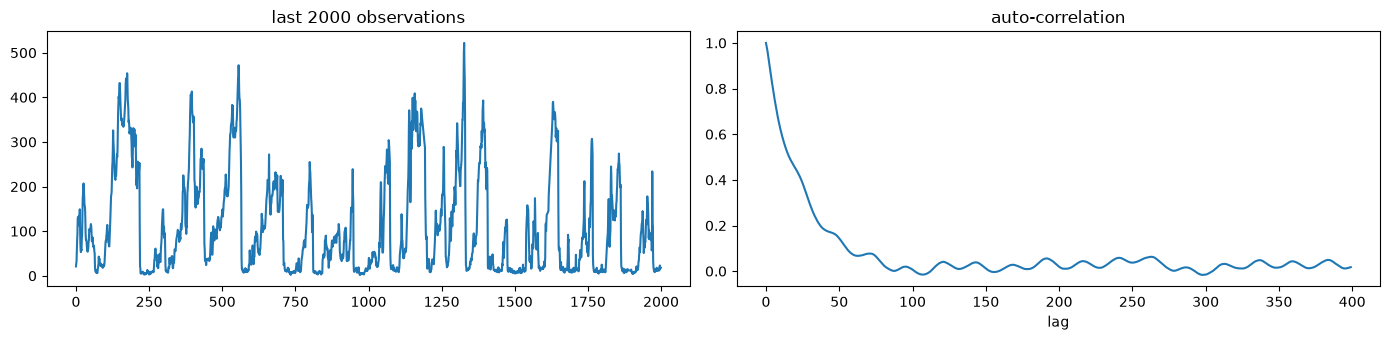

In [2]:
y = pd.read_csv("Data/student_train.csv").value.values.astype(np.float32)
X_raw = pd.read_csv("Data/optional_external_data.csv").iloc[:, 1:].values.astype(np.float32)
test_idx = pd.read_csv("Data/student_test.csv").time_idx.values
N = len(y)
assert N == 43656 and len(X_raw) == 43824 and test_idx[0] == 43657 and test_idx[-1] == 43824
print(f"train {N}, external {len(X_raw)}, mean {y.mean():.1f}, std {y.std():.1f}, max {y.max():.0f}")

# Recover the period without being told it: auto-correlation + periodogram
yc = y - y.mean()
f = np.fft.rfft(yc, 2 * N); acf = np.fft.irfft(f * np.conj(f))[:400]; acf /= acf[0]
power = np.abs(np.fft.rfft(yc)) ** 2; freq = np.fft.rfftfreq(N)
short = (freq > 1 / 200)
print("ACF at lags 1, 12, 24, 48, 168:", np.round(acf[[1, 12, 24, 48, 168]], 3))
print("dominant period below 200 steps:", round(1 / freq[short][power[short].argmax()], 1))

fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
ax[0].plot(y[-2000:]); ax[0].set_title("last 2000 observations")
ax[1].plot(acf); ax[1].set_title("auto-correlation"); ax[1].set_xlabel("lag")
plt.tight_layout(); plt.show()

## 2. Splits, scaling and covariates
Target: z-score with statistics from the training region only. Covariates: `log1p` on the heavy-tailed
accumulations (D, E, F), z-score, plus sin/cos phase of the recovered 24-step cycle and ~8766-step yearly cycle.

In [3]:
TEST0 = N - 52 * H
VAL0 = TEST0 - 26 * H
test_o, val_o = np.arange(TEST0, N, H), np.arange(VAL0, TEST0, H)

def make_covariates(X, fit_end):
    X = X.copy()
    X[:, 3:6] = np.log1p(X[:, 3:6])
    X = (X - X[:fit_end].mean(0)) / (X[:fit_end].std(0) + 1e-6)
    t = np.arange(len(X))
    phases = [fn(2 * np.pi * t / p)[:, None] for p in (24, 8766) for fn in (np.sin, np.cos)]
    return np.concatenate([X] + phases, 1).astype(np.float32)

targets = lambda origins: np.stack([y[o:o + H] for o in origins])
print("train origins end", VAL0 - H, "| val blocks", len(val_o), "| test blocks", len(test_o))

train origins end 30384 | val blocks 26 | test blocks 52


## 3. Autoformer

In [4]:
class SeriesDecomp(nn.Module):
    """Moving-average trend (edge-replicated) and seasonal remainder."""
    def __init__(self, k):
        super().__init__(); self.k = k
    def forward(self, x):                                    # [B, L, C]
        pad = (self.k - 1) // 2
        xp = torch.cat([x[:, :1].repeat(1, pad, 1), x, x[:, -1:].repeat(1, pad, 1)], 1)
        trend = F.avg_pool1d(xp.transpose(1, 2), self.k, stride=1).transpose(1, 2)
        return x - trend, trend


class AutoCorrelation(nn.Module):
    """Period-based dependencies via FFT auto-correlation; top-k = factor*log(L) delays aggregated by rolling V."""
    def __init__(self, d, heads, factor=1):
        super().__init__()
        self.h, self.factor = heads, factor
        self.q, self.k, self.v, self.o = (nn.Linear(d, d) for _ in range(4))

    def forward(self, xq, xkv):
        B, L, D = xq.shape
        q, k, v = self.q(xq), self.k(xkv), self.v(xkv)
        if xkv.shape[1] < L:                                 # zero-pad keys/values to query length
            pad = torch.zeros(B, L - xkv.shape[1], D, device=xq.device)
            k, v = torch.cat([k, pad], 1), torch.cat([v, pad], 1)
        else:
            k, v = k[:, :L], v[:, :L]
        q, k, v = (t.view(B, L, self.h, D // self.h).permute(0, 2, 3, 1) for t in (q, k, v))
        corr = torch.fft.irfft(torch.fft.rfft(q, dim=-1) * torch.conj(torch.fft.rfft(k, dim=-1)), n=L, dim=-1)
        score = corr.mean(dim=(1, 2))                        # [B, L]: one score per delay
        w, delay = torch.topk(score, int(self.factor * math.log(L)), dim=-1)
        w = torch.softmax(w, dim=-1)
        idx = (torch.arange(L, device=xq.device).view(1, 1, L) + delay.unsqueeze(-1)) % L
        vv = v.unsqueeze(1).expand(B, w.shape[1], *v.shape[1:])
        rolled = torch.gather(vv, -1, idx[:, :, None, None, :].expand_as(vv))
        out = (rolled * w[:, :, None, None, None]).sum(1)
        return self.o(out.permute(0, 3, 1, 2).reshape(B, L, D))


class SeasonalLayerNorm(nn.Module):
    def __init__(self, d):
        super().__init__(); self.ln = nn.LayerNorm(d)
    def forward(self, x):
        x = self.ln(x)
        return x - x.mean(1, keepdim=True)


def feed_forward(d, d_ff, drop):
    return nn.Sequential(nn.Conv1d(d, d_ff, 1, bias=False), nn.GELU(), nn.Dropout(drop), nn.Conv1d(d_ff, d, 1, bias=False))


class EncoderLayer(nn.Module):
    def __init__(self, d, heads, d_ff, k, drop):
        super().__init__()
        self.ac, self.ff = AutoCorrelation(d, heads), feed_forward(d, d_ff, drop)
        self.dec1, self.dec2, self.drop = SeriesDecomp(k), SeriesDecomp(k), nn.Dropout(drop)
    def forward(self, x):
        x, _ = self.dec1(x + self.drop(self.ac(x, x)))
        x, _ = self.dec2(x + self.drop(self.ff(x.transpose(1, 2)).transpose(1, 2)))
        return x


class DecoderLayer(nn.Module):
    def __init__(self, d, heads, d_ff, k, drop):
        super().__init__()
        self.self_ac, self.cross_ac, self.ff = AutoCorrelation(d, heads), AutoCorrelation(d, heads), feed_forward(d, d_ff, drop)
        self.dec1, self.dec2, self.dec3 = SeriesDecomp(k), SeriesDecomp(k), SeriesDecomp(k)
        self.drop = nn.Dropout(drop)
        self.trend_proj = nn.Conv1d(d, 1, 3, padding=1, padding_mode="circular", bias=False)
    def forward(self, x, enc):
        x, t1 = self.dec1(x + self.drop(self.self_ac(x, x)))
        x, t2 = self.dec2(x + self.drop(self.cross_ac(x, enc)))
        x, t3 = self.dec3(x + self.drop(self.ff(x.transpose(1, 2)).transpose(1, 2)))
        return x, self.trend_proj((t1 + t2 + t3).transpose(1, 2)).transpose(1, 2)


class Embedding(nn.Module):
    """Token embedding of the target + linear embedding of covariates (takes the place of Autoformer's calendar embedding)."""
    def __init__(self, n_cov, d, drop):
        super().__init__()
        self.val = nn.Conv1d(1, d, 3, padding=1, padding_mode="circular", bias=False)
        self.cov = nn.Linear(n_cov, d, bias=False)
        self.drop = nn.Dropout(drop)
    def forward(self, y, c):
        return self.drop(self.val(y.transpose(1, 2)).transpose(1, 2) + self.cov(c))


class Autoformer(nn.Module):
    def __init__(self, n_cov, trend_init="linear"):
        super().__init__()
        self.decomp = SeriesDecomp(KERNEL)
        self.enc_emb, self.dec_emb = Embedding(n_cov, D_MODEL, DROPOUT), Embedding(n_cov, D_MODEL, DROPOUT)
        self.encoder = EncoderLayer(D_MODEL, HEADS, D_FF, KERNEL, DROPOUT)
        self.decoder = DecoderLayer(D_MODEL, HEADS, D_FF, KERNEL, DROPOUT)
        self.enc_norm, self.dec_norm = SeasonalLayerNorm(D_MODEL), SeasonalLayerNorm(D_MODEL)
        self.proj = nn.Linear(D_MODEL, 1)
        # Trend initialisation for the horizon. Original Autoformer: window mean. "linear": a learned map
        # from the context trend to the horizon trend, initialised to exactly the window mean.
        self.trend_lin = None
        if trend_init == "linear":
            self.trend_lin = nn.Linear(SEQ_LEN, H)
            nn.init.constant_(self.trend_lin.weight, 1.0 / SEQ_LEN); nn.init.zeros_(self.trend_lin.bias)

    def forward(self, y_enc, c_enc, c_dec):
        # y_enc [B, SEQ, 1]; c_enc [B, SEQ, C] (past covariates); c_dec [B, LABEL+H, C] (incl. future covariates)
        seas, trend = self.decomp(y_enc)
        if self.trend_lin is None:
            future_trend = y_enc.mean(1, keepdim=True).repeat(1, H, 1)
        else:
            future_trend = self.trend_lin(trend[..., 0]).unsqueeze(-1)
        trend_init = torch.cat([trend[:, -LABEL_LEN:], future_trend], 1)
        seas_init = torch.cat([seas[:, -LABEL_LEN:], torch.zeros_like(future_trend)], 1)
        enc = self.enc_norm(self.encoder(self.enc_emb(y_enc, c_enc)))
        x, t = self.decoder(self.dec_emb(seas_init, c_dec), enc)
        return (self.proj(self.dec_norm(x)) + trend_init + t)[:, -H:, 0]


n_params = lambda m: sum(p.numel() for p in m.parameters() if p.requires_grad)
print("trainable parameters per model:", n_params(Autoformer(14)))

trainable parameters per model: 34377


## 4. Windows, training and metrics

In [5]:
class Windows:
    """Series and covariates on the GPU; a window is identified by its forecast origin o (first predicted index)."""
    def __init__(self, ys, C, use_cov=True):
        self.y, self.C, self.use_cov = torch.tensor(ys, device=DEVICE), torch.tensor(C, device=DEVICE), use_cov
    def batch(self, origins):
        o = torch.as_tensor(origins, device=DEVICE).view(-1, 1)
        ie = o - SEQ_LEN + torch.arange(SEQ_LEN, device=DEVICE)
        idd = o - LABEL_LEN + torch.arange(LABEL_LEN + H, device=DEVICE)
        it = o + torch.arange(H, device=DEVICE)
        ce, cd = self.C[ie], self.C[idd]
        if not self.use_cov:
            ce, cd = torch.zeros_like(ce), torch.zeros_like(cd)
        yt = self.y[it] if it.max() < len(self.y) else None
        return self.y[ie].unsqueeze(-1), ce, cd, yt


@torch.no_grad()
def predict(model, W, origins):
    model.eval()
    return torch.cat([model(*W.batch(origins[i:i + 256])[:3]) for i in range(0, len(origins), 256)]).cpu().numpy()


def metrics(p, t):
    p, t = np.asarray(p, float), np.asarray(t, float)
    return dict(RMSE=np.sqrt(np.mean((p - t) ** 2)), MAE=np.mean(np.abs(p - t)),
                sMAPE=100 * np.mean(2 * np.abs(p - t) / (np.abs(p) + np.abs(t) + 1e-8)))


def train(model, W, train_origins, epochs, val=None):
    """MSE training (matches the RMSE ranking). With val=(origins, inverse, targets): early stopping on val RMSE."""
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    best, best_ep, best_state, bad = np.inf, epochs, None, 0
    for ep in range(1, epochs + 1):
        model.train()
        perm = np.random.permutation(train_origins)
        for i in range(0, len(perm), BATCH):
            ye, ce, cd, yt = W.batch(perm[i:i + BATCH])
            loss = F.mse_loss(model(ye, ce, cd), yt)
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        if val is not None:
            r = metrics(val[1](predict(model, W, val[0])), val[2])["RMSE"]
            if r < best:
                best, best_ep, best_state, bad = r, ep, copy.deepcopy(model.state_dict()), 0
            else:
                bad += 1
                if bad >= PATIENCE:
                    break
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, best_ep

## 5. Validation experiments (3 seeds each)
| config | covariates | horizon trend init |
|---|---|---|
| `final` | yes (encoder past + decoder future) | learned linear |
| `no_external` | none (ablation) | learned linear |
| `mean_trend` | yes | window mean (original Autoformer) |

In [6]:
mu, sd = y[:VAL0].mean(), y[:VAL0].std()
inv = lambda p: p * sd + mu
C_val = make_covariates(X_raw, VAL0)
train_o = np.arange(SEQ_LEN, VAL0 - H + 1)
CONFIGS = {"final": (True, "linear"), "no_external": (False, "linear"), "mean_trend": (True, "mean")}

rows, test_preds = [], {}
for name, (use_cov, trend_init) in CONFIGS.items():
    W = Windows(((y - mu) / sd).astype(np.float32), C_val, use_cov)
    for s in SEEDS:
        set_seed(s); t0 = time.time()
        m, ep = train(Autoformer(C_val.shape[1], trend_init).to(DEVICE), W, train_o, MAX_EPOCHS,
                      (val_o, inv, targets(val_o)))
        p = inv(predict(m, W, test_o)); test_preds[(name, s)] = p
        rows.append(dict(config=name, seed=s, best_epoch=ep, params=n_params(m),
                         **metrics(p, targets(test_o)), sec=round(time.time() - t0)))
        print(rows[-1])
val_df = pd.DataFrame(rows)
summary = val_df.groupby("config")[["RMSE", "MAE", "sMAPE", "best_epoch"]].agg(["mean", "std"]).round(2)
summary

{'config': 'final', 'seed': 0, 'best_epoch': 4, 'params': 34377, 'RMSE': np.float64(65.20707423037152), 'MAE': np.float64(48.28493263869932), 'sMAPE': np.float64(64.68772785687831), 'sec': 66}


{'config': 'final', 'seed': 1, 'best_epoch': 3, 'params': 34377, 'RMSE': np.float64(64.80030529347253), 'MAE': np.float64(48.33884579707415), 'sMAPE': np.float64(64.68170205411793), 'sec': 52}


{'config': 'final', 'seed': 2, 'best_epoch': 5, 'params': 34377, 'RMSE': np.float64(64.60370526808966), 'MAE': np.float64(47.735610778951816), 'sMAPE': np.float64(64.38519178679758), 'sec': 69}


{'config': 'no_external', 'seed': 0, 'best_epoch': 2, 'params': 34377, 'RMSE': np.float64(87.2487758034071), 'MAE': np.float64(65.74034064680666), 'sMAPE': np.float64(72.96166167900526), 'sec': 44}


{'config': 'no_external', 'seed': 1, 'best_epoch': 3, 'params': 34377, 'RMSE': np.float64(86.04259429642535), 'MAE': np.float64(64.36279697950943), 'sMAPE': np.float64(72.10800569195077), 'sec': 53}


{'config': 'no_external', 'seed': 2, 'best_epoch': 1, 'params': 34377, 'RMSE': np.float64(86.79423222893061), 'MAE': np.float64(64.99710710668738), 'sMAPE': np.float64(72.5734109910607), 'sec': 35}


{'config': 'mean_trend', 'seed': 0, 'best_epoch': 3, 'params': 5985, 'RMSE': np.float64(75.99574072839091), 'MAE': np.float64(55.17682428936382), 'sMAPE': np.float64(69.04102739243996), 'sec': 52}


{'config': 'mean_trend', 'seed': 1, 'best_epoch': 9, 'params': 5985, 'RMSE': np.float64(72.67070613710602), 'MAE': np.float64(53.5628276853771), 'sMAPE': np.float64(69.8444292978182), 'sec': 104}


{'config': 'mean_trend', 'seed': 2, 'best_epoch': 8, 'params': 5985, 'RMSE': np.float64(75.86155654480244), 'MAE': np.float64(55.99341661109156), 'sMAPE': np.float64(69.587184367515), 'sec': 94}


RMSE          MAE        sMAPE       best_epoch      
              mean   std   mean   std   mean   std       mean   std
config                                                             
final        64.87  0.31  48.12  0.33  64.58  0.17       4.00  1.00
mean_trend   74.84  1.88  54.91  1.24  69.49  0.41       6.67  3.21
no_external  86.70  0.61  65.03  0.69  72.55  0.43       2.00  1.00

In [7]:
# Ensemble of the 3 seeds of each config, and non-negativity clipping (the target is a non-negative quantity)
ens = []
for name in CONFIGS:
    p = np.mean([test_preds[(name, s)] for s in SEEDS], 0)
    ens.append(dict(config=name, **{f"ens_{k}": v for k, v in metrics(p, targets(test_o)).items()},
                    **{f"ens_clip_{k}": v for k, v in metrics(np.clip(p, 0, None), targets(test_o)).items()}))
pd.DataFrame(ens).round(2)

,config,ens_RMSE,ens_MAE,ens_sMAPE,ens_clip_RMSE,ens_clip_MAE,ens_clip_sMAPE
0,final,63.52,47.01,63.13,62.25,45.06,63.13
1,no_external,86.51,64.93,72.50,86.51,64.93,72.50
2,mean_trend,71.73,52.02,66.27,71.18,50.84,66.27


external data better on 44 / 52 blocks


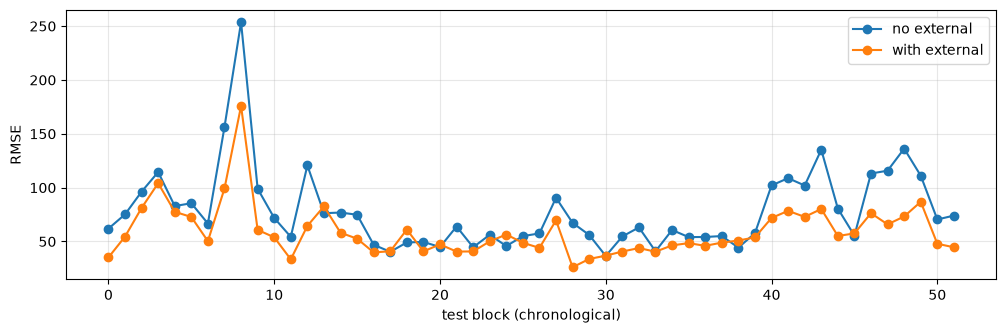

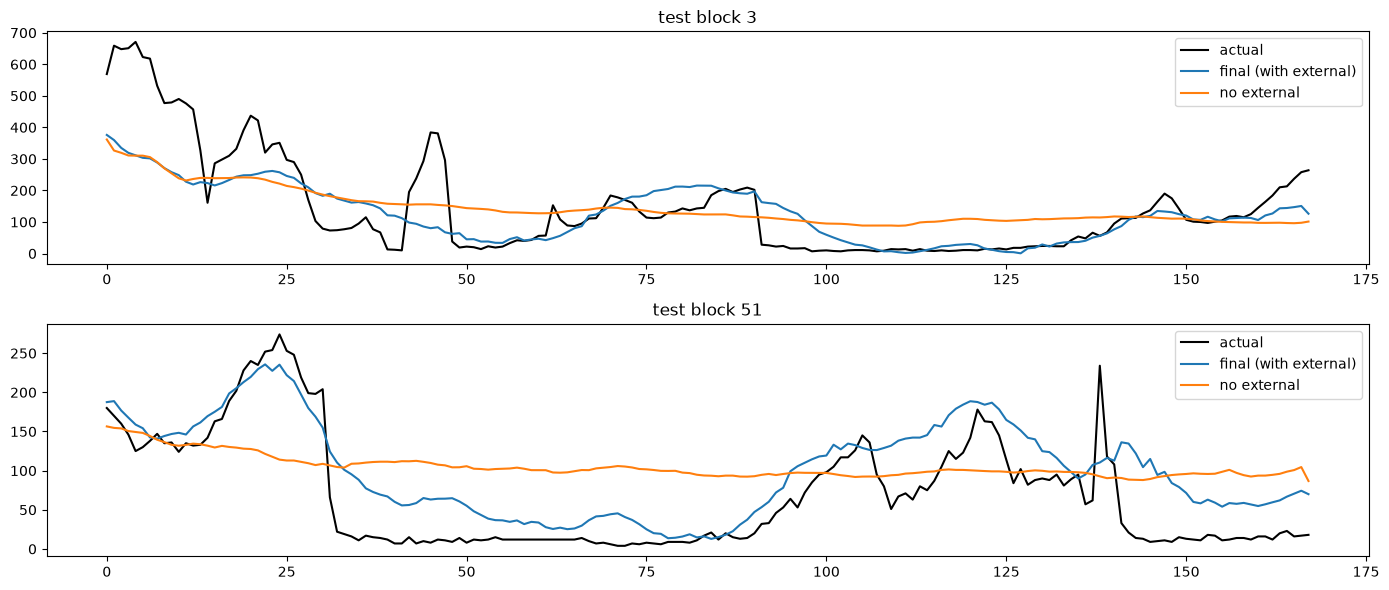

In [8]:
# Per-block RMSE: with vs without the external file (same 52 blocks, 3-seed ensembles)
blk = lambda name: np.sqrt(((np.mean([test_preds[(name, s)] for s in SEEDS], 0) - targets(test_o)) ** 2).mean(1))
b_with, b_without = blk("final"), blk("no_external")
print(f"external data better on {(b_with < b_without).sum()} / {len(b_with)} blocks")
plt.figure(figsize=(12, 3.5))
plt.plot(b_without, "o-", label="no external"); plt.plot(b_with, "o-", label="with external")
plt.xlabel("test block (chronological)"); plt.ylabel("RMSE"); plt.legend(); plt.grid(alpha=.3); plt.show()

fig, axes = plt.subplots(2, 1, figsize=(14, 6))
for ax, b in zip(axes, [np.argmax(targets(test_o).std(1)), len(test_o) - 1]):
    ax.plot(targets(test_o)[b], "k", label="actual")
    ax.plot(np.mean([test_preds[("final", s)] for s in SEEDS], 0)[b], label="final (with external)")
    ax.plot(np.mean([test_preds[("no_external", s)] for s in SEEDS], 0)[b], label="no external")
    ax.set_title(f"test block {b}"); ax.legend()
plt.tight_layout(); plt.show()

## 6. Refit check
Final forecasts come from models refit with a **fixed** number of epochs (median early-stopping epoch of `final`).
Before trusting that, simulate it: refit on everything before the test blocks for that many epochs and score the
3-seed clipped ensemble on the 52 test blocks.

In [9]:
FINAL_EPOCHS = int(np.median(val_df.query("config == 'final'").best_epoch))
ES_EPOCHS = int(val_df.query("config == 'final'").best_epoch.sum())
print("FINAL_EPOCHS =", FINAL_EPOCHS, "| early-stopping epochs of the chosen config =", ES_EPOCHS)

mu_r, sd_r = y[:TEST0].mean(), y[:TEST0].std()
W = Windows(((y - mu_r) / sd_r).astype(np.float32), make_covariates(X_raw, TEST0))
P = []
for s in SEEDS:
    set_seed(s)
    m, _ = train(Autoformer(14).to(DEVICE), W, np.arange(SEQ_LEN, TEST0 - H + 1), FINAL_EPOCHS)
    P.append(predict(m, W, test_o) * sd_r + mu_r)
    print(s, {k: round(v, 2) for k, v in metrics(P[-1], targets(test_o)).items()})
print("refit 3-seed ensemble, clipped:", {k: round(v, 2) for k, v in metrics(np.clip(np.mean(P, 0), 0, None), targets(test_o)).items()})

FINAL_EPOCHS = 4 | early-stopping epochs of the chosen config = 12


0 {'RMSE': np.float64(64.74), 'MAE': np.float64(47.35), 'sMAPE': np.float64(62.47)}


1 {'RMSE': np.float64(64.22), 'MAE': np.float64(46.92), 'sMAPE': np.float64(62.12)}


2 {'RMSE': np.float64(63.57), 'MAE': np.float64(46.46), 'sMAPE': np.float64(63.03)}
refit 3-seed ensemble, clipped: {'RMSE': np.float64(61.99), 'MAE': np.float64(44.26), 'sMAPE': np.float64(61.47)}


## 7. Final refit on all 43,656 observations and the 168-step forecast

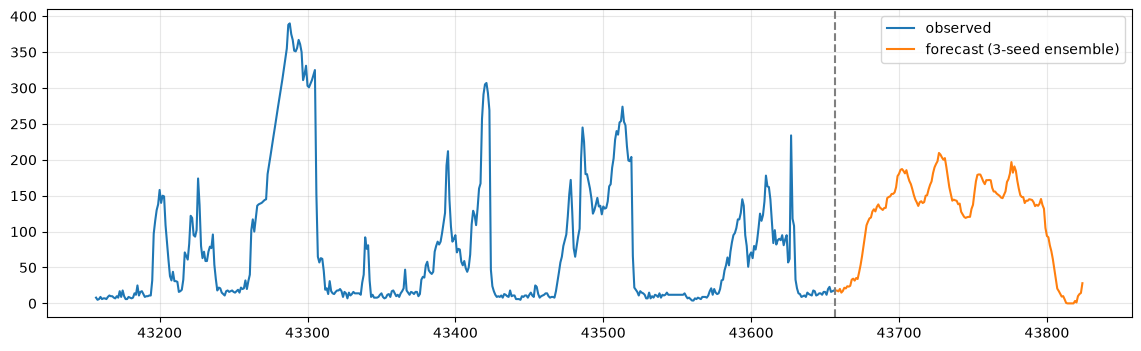

In [10]:
mu_f, sd_f = y.mean(), y.std()
C_full = make_covariates(X_raw, N)                    # covers the 168 hidden steps as well
W = Windows(((y - mu_f) / sd_f).astype(np.float32), C_full)
final_models, forecasts = [], []
for s in SEEDS:
    set_seed(s)
    m, _ = train(Autoformer(14).to(DEVICE), W, np.arange(SEQ_LEN, N - H + 1), FINAL_EPOCHS)
    final_models.append(m)
    forecasts.append(predict(m, W, np.array([N]))[0] * sd_f + mu_f)
    torch.save(m.state_dict(), f"final_autoformer_seed{s}.pt")
forecast = np.clip(np.mean(forecasts, 0), 0, None)

TOTAL_PARAMS = sum(n_params(m) for m in final_models)
TOTAL_EPOCHS = ES_EPOCHS + FINAL_EPOCHS * len(SEEDS)
assert len(forecast) == H and np.isfinite(forecast).all()

plt.figure(figsize=(14, 4))
plt.plot(np.arange(N - 500, N) + 1, y[-500:], label="observed")
plt.plot(test_idx, forecast, label="forecast (3-seed ensemble)")
plt.axvline(N + 0.5, ls="--", c="gray"); plt.legend(); plt.grid(alpha=.3); plt.show()

In [11]:
pd.DataFrame({"time_idx": test_idx, "prediction": forecast}).to_csv("task2_predictions.csv", index=False)
submission = ", ".join(f"{v:.4f}" for v in forecast)
assert len(submission.split(",")) == 168

print("=" * 60)
print("Trainable parameters P :", TOTAL_PARAMS, f"(= {len(SEEDS)} x {n_params(final_models[0])})")
print("Training epochs E      :", TOTAL_EPOCHS, f"(= {ES_EPOCHS} early-stopping + {len(SEEDS)} x {FINAL_EPOCHS} refit)")
print("=" * 60)
print(submission)

Trainable parameters P : 103131 (= 3 x 34377)
Training epochs E      : 24 (= 12 early-stopping + 3 x 4 refit)
17.5858, 17.9795, 16.6576, 20.1517, 15.0256, 17.2940, 21.7893, 20.8473, 23.8543, 23.3128, 24.4791, 33.0070, 34.4020, 31.7392, 35.2937, 33.9949, 43.2844, 53.4805, 65.8780, 79.7867, 94.3415, 108.7054, 113.9361, 118.3487, 119.5996, 128.0056, 131.1049, 128.0853, 134.5583, 137.8500, 133.6689, 131.8056, 130.1213, 132.9161, 133.0723, 146.6313, 148.1949, 149.0349, 152.4107, 152.5374, 154.5330, 161.7523, 177.2692, 180.5292, 186.0196, 187.1055, 184.5143, 181.1102, 185.5342, 176.9195, 170.4098, 166.1048, 159.0498, 151.0490, 144.7820, 140.6321, 135.7438, 140.8992, 142.2872, 139.7889, 141.0925, 149.9089, 150.7010, 158.7870, 165.1562, 169.8707, 181.3897, 189.4263, 194.1285, 197.9015, 209.5274, 207.3086, 203.3513, 200.0291, 202.3686, 189.9557, 176.3486, 161.8403, 152.3856, 143.0780, 144.4837, 143.5567, 142.8908, 138.0656, 139.0438, 127.6145, 123.9404, 120.5738, 119.0784, 120.0384, 120.5323, 1